In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('IRIS.csv')

# --- PERBAIKAN NAMA KOLOM, biar tidak KeyError lagi ---
# Bersihkan spasi + samakan nama kolom
df.columns = [c.strip() for c in df.columns]

# Kalau kolomnya 'species' kecil, ubah jadi 'Species'
if 'species' in df.columns:
    df = df.rename(columns={'species': 'Species'})
if 'Species ' in df.columns:
    df = df.rename(columns={'Species ': 'Species'})

# Kalau ada kolom Id / id, hapus
for col in ['Id', 'id', 'ID']:
    if col in df.columns:
        df = df.drop(col, axis=1)

print("=== IDENTIFIKASI DATASET ===")
print("Nama Dataset: Iris Flower")
print("Sumber: Kaggle - uciml/iris")
print("Jenis Data: Tabular / Angka (Bukan Teks, Bukan Image)")
print(f"Jumlah Data (baris): {df.shape[0]}")
print(f"Jumlah Variabel (kolom): {df.shape[1]}")
print(f"Nama Variabel: {list(df.columns)}")
print(f"Data Fitur (X): {list(df.drop('Species', axis=1).columns)}")
print(f"Data Target (y): ['Species']")
print(f"Isi Label: {sorted(df['Species'].unique())}")
print("\nKESIMPULAN SEMENTARA: Klasifikasi MULTIKELAS")
print(df.head())

=== IDENTIFIKASI DATASET ===
Nama Dataset: Iris Flower
Sumber: Kaggle - uciml/iris
Jenis Data: Tabular / Angka (Bukan Teks, Bukan Image)
Jumlah Data (baris): 150
Jumlah Variabel (kolom): 5
Nama Variabel: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'Species']
Data Fitur (X): ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
Data Target (y): ['Species']
Isi Label: ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']

KESIMPULAN SEMENTARA: Klasifikasi MULTIKELAS
   sepal_length  sepal_width  petal_length  petal_width      Species
0           5.1          3.5           1.4          0.2  Iris-setosa
1           4.9          3.0           1.4          0.2  Iris-setosa
2           4.7          3.2           1.3          0.2  Iris-setosa
3           4.6          3.1           1.5          0.2  Iris-setosa
4           5.0          3.6           1.4          0.2  Iris-setosa


Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


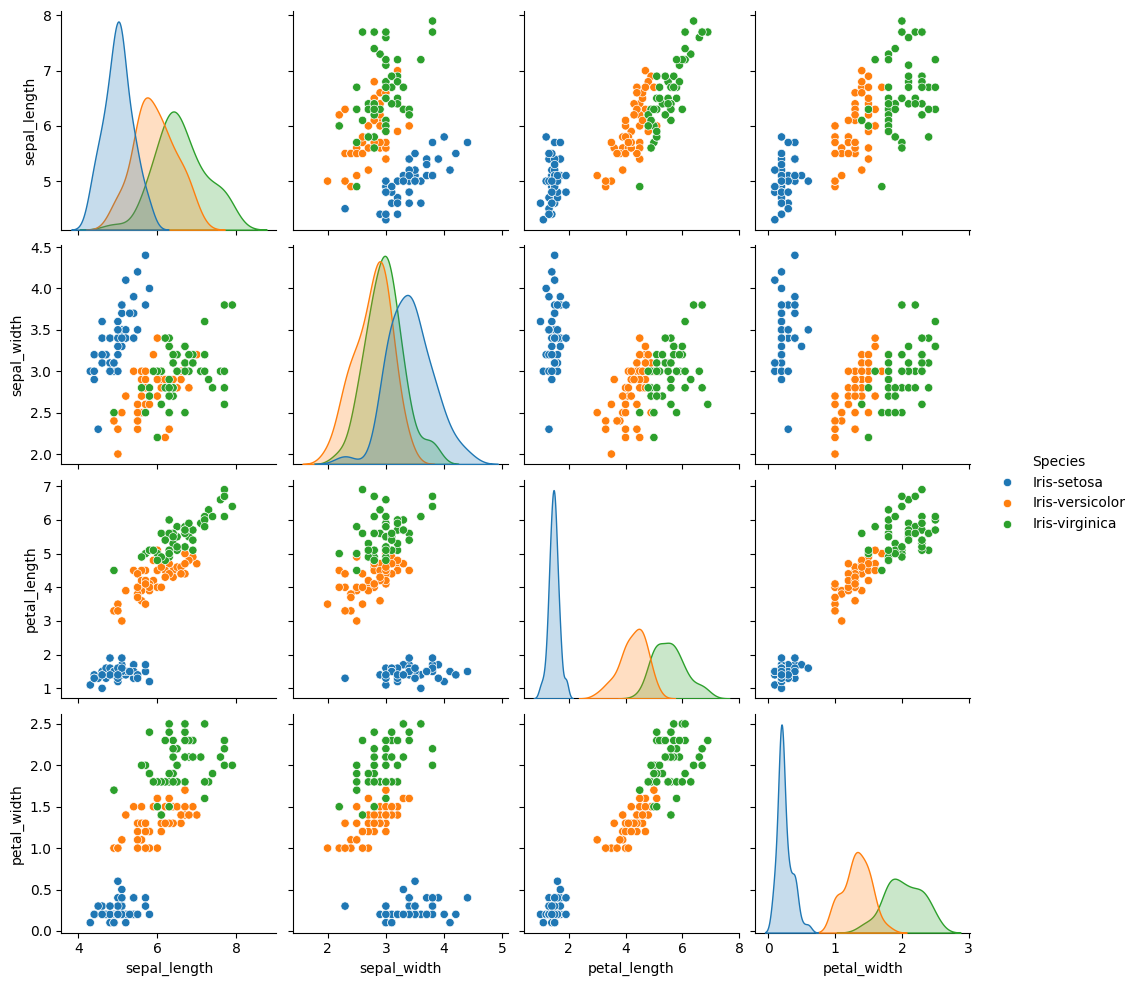

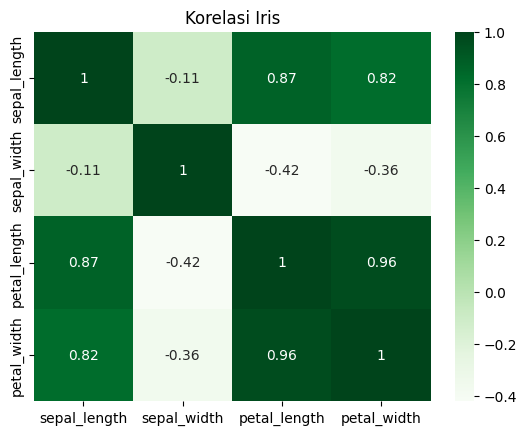

In [9]:
print(df['Species'].value_counts())
sns.pairplot(df, hue='Species')
plt.show()
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='Greens')
plt.title('Korelasi Iris')
plt.show()

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

X = df.drop('Species', axis=1)
y = LabelEncoder().fit_transform(df['Species'])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")

X_train: (120, 4), X_test: (30, 4)


In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

m1 = RandomForestClassifier(n_estimators=100, random_state=42)
m1.fit(X_train_s, y_train)
p1 = m1.predict(X_test_s)
print("Random Forest Accuracy:", accuracy_score(y_test, p1))

m2 = KNeighborsClassifier(n_neighbors=3)
m2.fit(X_train_s, y_train)
p2 = m2.predict(X_test_s)
print("KNN Accuracy:", accuracy_score(y_test, p2))

y_pred = p1 if accuracy_score(y_test, p1) >= accuracy_score(y_test, p2) else p2
print("Model Terbaik dipilih")

Random Forest Accuracy: 0.9
KNN Accuracy: 0.9333333333333333
Model Terbaik dipilih


              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



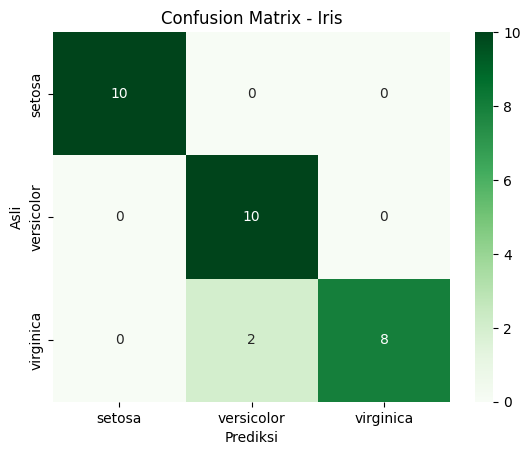

=== KESIMPULAN AKHIR ===
Jenis Klasifikasi: MULTIKELAS, karena target ada 3 kelas dan 1 data hanya masuk 1 kelas
Accuracy Akhir: 0.9333


In [12]:
print(classification_report(y_test, y_pred, target_names=['setosa','versicolor','virginica']))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Greens', xticklabels=['setosa','versicolor','virginica'], yticklabels=['setosa','versicolor','virginica'])
plt.title('Confusion Matrix - Iris')
plt.xlabel('Prediksi')
plt.ylabel('Asli')
plt.show()

print("=== KESIMPULAN AKHIR ===")
print("Jenis Klasifikasi: MULTIKELAS, karena target ada 3 kelas dan 1 data hanya masuk 1 kelas")
print(f"Accuracy Akhir: {accuracy_score(y_test, y_pred):.4f}")